# Week 6 — Decision Trees and Random Forests
It closes the three questions the earlier weeks left open:

- **RQ1 (primary):** Week 5's curved SVM flattened Week 4's U-shape across horizons. Does a second, different kind of
  non-linear model agree?
- **RQ2:** which families carry the signal? Lasso (Week 2) and subset selection (Week 3) agreed on activity ratios.
  Random-forest importance is the **third method**.
- **RQ3:** do the same families matter in the Taiwanese data?

**Trees in one line:** a decision tree asks a series of yes/no questions ("is the quick ratio below 0.3?") and sorts
firms into groups. It works through **thresholds** — exactly what Week 5's decile check found in the data.

## Datasets used

- **Polish Companies Bankruptcy** — UCI, DOI [10.24432/C5F600](https://doi.org/10.24432/C5F600).
  - **Main file:** `polish_predict_3y.csv` — Steps 1–7. Same cleaning, 78 columns and train/test split as Weeks 2–5
    (the same 2,084 test firms).
  - **All five horizons:** `polish_predict_1y.csv` … `polish_predict_5y.csv` — Steps 8–9 (RQ1, RQ2 by horizon).
    Each modelled separately.
- **Taiwanese Bankruptcy Prediction** — UCI, DOI [10.24432/C5004D](https://doi.org/10.24432/C5004D).
  - **File used:** `taiwanese_bankruptcy.csv`, cleaned as in Week 4 (values above 1 → missing + flag) — Step 10 (RQ3).
- **Not used:** the credit card data — RQ4 was answered in Week 4.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score

DATA = Path("../Dataset_new/CSV")
pd.set_option("display.width", 120)

## Step 1 — Load the data (same cleaning as Weeks 2–5)

In [2]:
COPIES = ["prof_gross_interest_assets", "prof_gross_profit_assets", "act_receivables_inv_days"]
DROP   = ["liq_quick_to_lt_liab", "grow_sales_growth"]

def load_polish(h):
    # One horizon: remove duplicate rows, drop copied / high-blank columns, add blank-pattern flags
    df = pd.read_csv(DATA / f"polish_predict_{h}y.csv")
    all64 = [c for c in df.columns if c not in ("class", "years_ahead")]
    df = df.drop_duplicates(subset=all64).reset_index(drop=True)
    cols = [c for c in all64 if c not in COPIES + DROP]
    blank = df[all64].isna()
    blank = blank.loc[:, blank.any()]
    for c in blank.T.drop_duplicates().index:
        df["blank_" + c] = df[c].isna().astype(int)
        cols.append("blank_" + c)
    return df[cols], df["class"]

def load_taiwan():
    # Week 4 cleaning: values above the documented 0–1 range → missing + "out_" flag
    tw = pd.read_csv(DATA / "taiwanese_bankruptcy.csv")
    X = tw[[c for c in tw.columns if c not in ("Bankrupt?", "Net Income Flag")]].copy()
    for c in [c for c in X.columns if (X[c] > 1).any()]:
        X["out_" + c] = (X[c] > 1).astype(int)
        X.loc[X[c] > 1, c] = np.nan
    return X, tw["Bankrupt?"]

X, y = load_polish(3)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(f"Polish 3y: {X.shape[1]} columns · train {len(X_train)} firms ({y_train.sum()} bankrupt) · "
      f"test {len(X_test)} firms ({y_test.sum()} bankrupt)")

Polish 3y: 78 columns · train 8332 firms (394 bankrupt) · test 2084 firms (99 bankrupt)


## Step 2 — How trees work, and the setup

- **A decision tree** splits the firms with one yes/no question at a time, choosing each question to separate bankrupt
  from surviving firms as cleanly as possible. A firm's risk = the bankruptcy rate in the group it ends up in.
- **Depth** = how many questions in a row. A deep tree can keep splitting until every group is pure — it memorises.
- **A random forest** grows hundreds of trees, each on a random sample of firms and allowed to look at only some
  columns at each split, then **averages** them. The averaging cancels out each tree's memorising.

**No scaling needed.** A tree only asks "above or below this value?", so the ratio's units don't matter — unlike
Weeks 2–5. Blanks are still filled with the median (scikit-learn trees need complete data).

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
SCORES = {"train_PR_AUC": 3, "val_PR_AUC": 3, "val_sd": 3, "gap": 3}

def tree_pipe(clf):
    return make_pipeline(SimpleImputer(strategy="median"), clf)

def run_cv(model, X=X_train, y=y_train, cv=cv):
    r = cross_validate(model, X, y, cv=cv, scoring="average_precision", return_train_score=True, n_jobs=5)
    return {"train_PR_AUC": r["train_score"].mean(), "val_PR_AUC": r["test_score"].mean(),
            "val_sd": r["test_score"].std(), "gap": r["train_score"].mean() - r["test_score"].mean()}

## Step 3 — A single decision tree: depth vs overfitting

Depth from 2 to unlimited. Watch train and validation separate as the tree grows.

In [4]:
DEPTHS = [2, 3, 4, 5, 6, 8, 10, 15, None]
tree_table = pd.DataFrame([{"max_depth": "none" if d is None else d,
                            **run_cv(tree_pipe(DecisionTreeClassifier(max_depth=d, random_state=0)))}
                           for d in DEPTHS])
tree_table.round(SCORES)

,max_depth,train_PR_AUC,val_PR_AUC,val_sd,gap
0,2,0.271,0.268,0.054,0.003
1,3,0.404,0.350,0.049,0.054
2,4,0.480,0.368,0.052,0.112
3,5,0.540,0.365,0.063,0.175
4,6,0.605,0.338,0.066,0.267
5,8,0.712,0.293,0.067,0.418
6,10,0.784,0.274,0.061,0.511
7,15,0.907,0.233,0.043,0.673
8,none,1.000,0.189,0.030,0.811


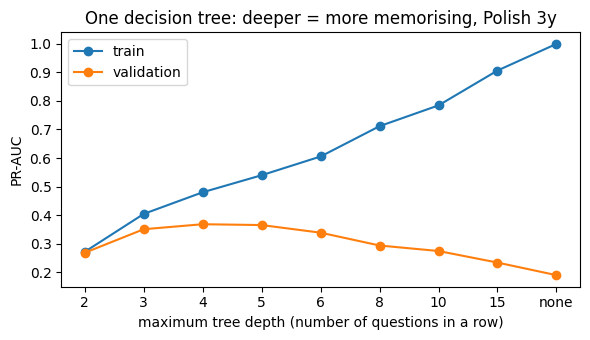

In [5]:
# Figure candidate: the classic overfitting picture
labels = [str(d) for d in tree_table["max_depth"]]
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(labels, tree_table["train_PR_AUC"], "o-", label="train")
ax.plot(labels, tree_table["val_PR_AUC"], "o-", label="validation")
ax.set_xlabel("maximum tree depth (number of questions in a row)")
ax.set_ylabel("PR-AUC")
ax.set_title("One decision tree: deeper = more memorising, Polish 3y")
ax.legend()
plt.tight_layout()
plt.show()

**What we found:**
- **Validation peaks at depth 4 (0.368)**, then falls steadily: depth 8 0.293, depth 15 0.233, no limit **0.189**.
- **Training keeps rising to a perfect 1.000** with no depth limit — the tree memorises every training firm.
- The gap grows from 0.003 (depth 2) to **0.811** (no limit) — the clearest overfitting picture in the project.
- **Depth is the regulariser:** limiting it to 3–5 questions keeps the tree general.

## Step 4 — What a small tree actually asks

A depth-3 tree fitted on all training firms. Each box shows the question, how many firms reach it, and the share of
bankrupt firms (`value`). Because there is no scaling, the thresholds are in the ratios' **real units**.

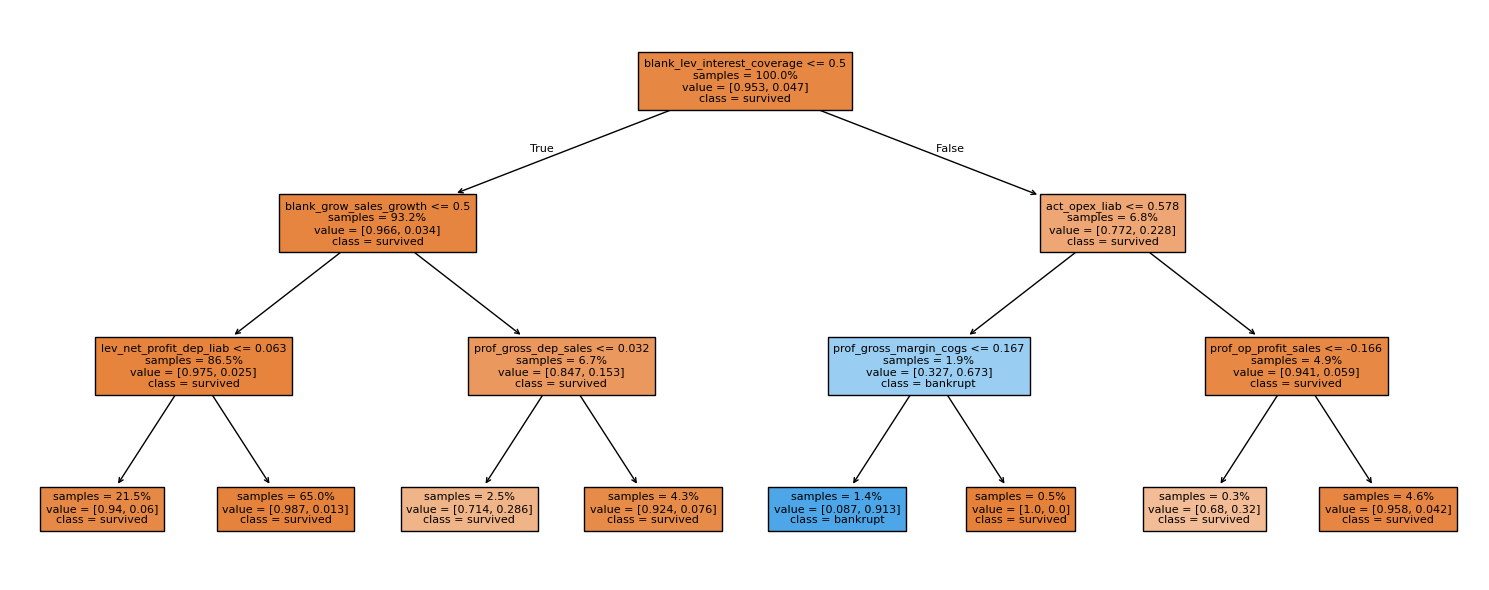

In [6]:
small_tree = tree_pipe(DecisionTreeClassifier(max_depth=3, random_state=0)).fit(X_train, y_train)
fig, ax = plt.subplots(figsize=(15, 6))
plot_tree(small_tree[-1], feature_names=list(X_train.columns), class_names=["survived", "bankrupt"],
          filled=True, proportion=True, impurity=False, fontsize=8, ax=ax)
plt.tight_layout()
plt.show()

**What we found:**
- **The first question is "was interest coverage left blank?"** — a missing value, not a ratio. Blank patterns
  matter most, as in Weeks 2–4.
- **The riskiest group:** interest coverage blank → operating expenses relative to liabilities ≤ 0.58 → gross margin
  relative to costs ≤ 0.17 → **105 of 115 firms went bankrupt** (91%, against 4.7% overall).
- Firms with interest coverage reported and sales growth reported: 179 bankrupt out of 7,206 (2.5%).
- **Every rule is a threshold** ("below 0.17"), matching Week 5's decile check — risk sits at the extremes.
- A tree this small is readable as a credit-committee checklist, but it scores only 0.35–0.37.

## Step 5 — Random forest: tuning

Two hyperparameters, 300 trees each:
- **`max_features`** — how many columns each split may look at: `sqrt` (about 9 of 78), 30% or 50%. Fewer = trees
  more different from each other = more benefit from averaging.
- **`min_samples_leaf`** — the smallest group a tree may end on: 1, 5 or 20 firms. Larger = less memorising.

About 1–2 minutes.

In [7]:
rf_rows = []
for mf in ["sqrt", 0.3, 0.5]:
    for leaf in [1, 5, 20]:
        rf = RandomForestClassifier(n_estimators=300, max_features=mf, min_samples_leaf=leaf, n_jobs=2, random_state=0)
        rf_rows.append({"max_features": mf, "min_samples_leaf": leaf, **run_cv(tree_pipe(rf))})
rf_table = pd.DataFrame(rf_rows)
best_rf = rf_table.loc[rf_table["val_PR_AUC"].idxmax()]
print(f"Best: max_features = {best_rf['max_features']}, min_samples_leaf = {best_rf['min_samples_leaf']} "
      f"→ validation {best_rf['val_PR_AUC']:.3f}, gap {best_rf['gap']:.3f}")
rf_table.round(SCORES)

Best: max_features = 0.5, min_samples_leaf = 5 → validation 0.545, gap 0.433


,max_features,min_samples_leaf,train_PR_AUC,val_PR_AUC,val_sd,gap
0,sqrt,1,1.000,0.462,0.055,0.538
1,sqrt,5,0.986,0.499,0.052,0.487
2,sqrt,20,0.750,0.461,0.051,0.289
3,0.3,1,1.000,0.513,0.054,0.487
4,0.3,5,0.982,0.540,0.052,0.441
5,0.3,20,0.757,0.515,0.050,0.241
6,0.5,1,1.000,0.517,0.066,0.483
7,0.5,5,0.977,0.545,0.053,0.433
8,0.5,20,0.757,0.523,0.053,0.234


**What we found:**
- **Best: max_features = 0.5, min_samples_leaf = 5 → validation 0.545** — far above one tree (0.368).
  Averaging many different trees cancels each tree's memorising.
- **`min_samples_leaf` is the main overfitting control:** leaves of 1 firm give train 1.000 (gap ~0.48–0.54);
  leaves of 20 cut the gap to ~0.23–0.29 for a small loss in validation (0.52 vs 0.545).
- **Letting splits see more columns helps** (sqrt ≈ 9 columns: 0.499 → 50%: 0.545), probably because only a few
  columns carry most of the signal (Week 3).
- Even the best forest has a large gap (0.43) — it fits training firms almost perfectly but still generalises well.

## Step 6 — Final comparison on the test set

Same test firms as Weeks 2–5. Logistic regression (Week 4) and the RBF SVM (Week 5, C = 1000, gamma = 0.001) are
refitted here so all four are scored on exactly the same firms. 95% ranges from 1,000 re-draws of the test set.

In [8]:
def scaled(clf):
    # Weeks 2–5 preparation for the linear model and the SVM
    return make_pipeline(SimpleImputer(strategy="median"),
                         QuantileTransformer(output_distribution="normal", n_quantiles=1000, random_state=0), clf)

def rf_model():
    return tree_pipe(RandomForestClassifier(n_estimators=500, max_features=best_rf["max_features"],
                                            min_samples_leaf=int(best_rf["min_samples_leaf"]),
                                            n_jobs=-1, random_state=0))

final = {
    "logistic regression (Week 4)":   scaled(LogisticRegression(max_iter=5000)),
    "RBF SVM (Week 5)":               scaled(SVC(kernel="rbf", C=1000, gamma=0.001)),
    "decision tree (depth 4)":        tree_pipe(DecisionTreeClassifier(max_depth=4, random_state=0)),
    "random forest (500 trees)":      rf_model(),
}

def score(model, X):
    return model.decision_function(X) if hasattr(model[-1], "decision_function") else model.predict_proba(X)[:, 1]

rng = np.random.default_rng(0)
yt = y_test.to_numpy()
boot = [rng.integers(0, len(yt), len(yt)) for _ in range(1000)]

rows, fitted = [], {}
for name, m in final.items():
    m.fit(X_train, y_train)
    fitted[name] = m
    p_tr, p_te = score(m, X_train), score(m, X_test)
    tr, te = average_precision_score(y_train, p_tr), average_precision_score(yt, p_te)
    lo, hi = np.percentile([average_precision_score(yt[i], p_te[i]) for i in boot], [2.5, 97.5])
    rows.append({"model": name, "train_PR_AUC": tr, "test_PR_AUC": te, "test_95%_range": f"{lo:.3f}–{hi:.3f}",
                 "gap": tr - te, "test_lift": te / yt.mean()})
comparison = pd.DataFrame(rows)
comparison.round(3)

,model,train_PR_AUC,test_PR_AUC,test_95%_range,gap,test_lift
0,logistic regression (Week 4),0.469,0.485,0.386–0.596,-0.016,10.206
1,RBF SVM (Week 5),0.953,0.715,0.622–0.802,0.237,15.054
2,decision tree (depth 4),0.469,0.480,0.369–0.582,-0.011,10.101
3,random forest (500 trees),0.979,0.674,0.585–0.752,0.305,14.184


**What we found:**
- **RBF SVM 0.715 · random forest 0.674 · logistic 0.485 · single tree 0.480.**
- **The forest confirms Week 5:** a second, completely different curved model also beats the straight line by a wide
  margin (lift 14.2× vs 10.2×).
- RBF SVM stays slightly ahead, but the ranges overlap (0.62–0.80 vs 0.59–0.75), so the two are statistically level.
- **One tree is no better than logistic regression** (0.480 vs 0.485): a single tree is too crude; the gain comes from averaging many.
- Train–test gaps: forest 0.31, RBF 0.24 — both fit training firms closely yet score highest on new ones.

## Step 7 — RQ2: which families does the forest rely on?

**Method: scramble a whole family and measure the damage.**
1. Score the fitted forest on the test firms.
2. Shuffle all columns of one family (e.g. every `act_` ratio) across firms — the forest can no longer use that
   family's information.
3. The drop in PR-AUC = how much the forest relies on that family. Repeated 10 times per family.

**Why whole families, not single columns:** if one near-copy is scrambled, the forest just uses its twin, so each
looks unimportant on its own (the Week 1–3 problem again). Scrambling the whole family removes the information completely.

In [9]:
def family(name):
    return name.split("_")[0]   # prof, lev, act, liq, size, blank

def family_importance(model, X, y, families, n_repeats=10, seed=0):
    # Drop in PR-AUC when every column of one family is shuffled together
    rng = np.random.default_rng(seed)
    base = average_precision_score(y, score(model, X))
    rows = []
    for fam, cols in families.items():
        drops = []
        for _ in range(n_repeats):
            Xs = X.copy()
            Xs[cols] = Xs[cols].to_numpy()[rng.permutation(len(Xs))]
            drops.append(base - average_precision_score(y, score(model, Xs)))
        rows.append({"family": fam, "n_columns": len(cols), "PR_AUC_drop": np.mean(drops), "drop_sd": np.std(drops)})
    return pd.DataFrame(rows).sort_values("PR_AUC_drop", ascending=False).reset_index(drop=True)

POLISH_FAMILIES = {}
for c in X_train.columns:
    POLISH_FAMILIES.setdefault(family(c), []).append(c)

rf_fitted = fitted["random forest (500 trees)"]
fam_imp = family_importance(rf_fitted, X_test, y_test, POLISH_FAMILIES)
fam_imp["drop_per_column"] = fam_imp["PR_AUC_drop"] / fam_imp["n_columns"]
fam_imp.round(3)

,family,n_columns,PR_AUC_drop,drop_sd,drop_per_column
0,blank,19,0.524,0.014,0.028
1,act,14,0.273,0.020,0.020
2,prof,19,0.105,0.017,0.006
3,lev,16,0.103,0.014,0.006
4,liq,9,0.069,0.005,0.008
5,size,1,0.005,0.003,0.005


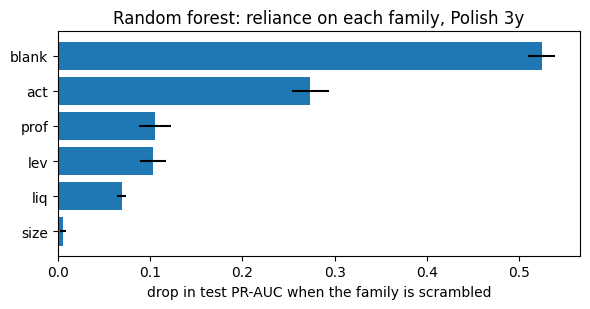

In [10]:
# Figure candidate: how much the forest loses when each family is scrambled
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.barh(fam_imp["family"][::-1], fam_imp["PR_AUC_drop"][::-1], xerr=fam_imp["drop_sd"][::-1])
ax.set_xlabel("drop in test PR-AUC when the family is scrambled")
ax.set_title("Random forest: reliance on each family, Polish 3y")
plt.tight_layout()
plt.show()

**Compare with the earlier methods** (share of each family's columns kept — Weeks 2–3):
- **Lasso (Week 2):** activity 64% · blank 53% · liquidity 33% · leverage 31% · profitability 26% (kept in all 5 folds).
- **Forward selection (Week 3):** activity 36% · blank 32% · liquidity 22% · leverage 6% · profitability 5%.
- **Backward elimination (Week 3):** activity 36% · liquidity 22% · blank 21% · leverage 12% · profitability 0%.

**What we found:**
- **Scrambling a family costs:** blank flags **0.524** · activity **0.273** · profitability 0.105 · leverage 0.103 ·
  liquidity 0.069 · size 0.005.
- **Activity is the top financial family** — the same as lasso, forward and backward. **All three methods agree.**
- **Blank patterns matter even more** than any ratio family — consistent with every week since Week 2.
- **Per column**, activity (0.020) is more than three times profitability (0.006) and leverage (0.006).
- **One difference:** the forest ranks liquidity last among the ratio families (0.069), while the selection methods
  placed it in the middle (22–33% kept). The quick ratio was forward selection's first pick, so liquidity's
  information may also be carried by other columns the forest can use.

## Step 8 — RQ1: does a forest confirm the flatter horizon pattern?

Logistic regression, the RBF SVM and the random forest on all five horizons, 5 folds × 2 repeats.
Same settings at every horizon (chosen on the 3-year file); the forest uses 200 trees here to keep the run time down.
**Normalised PR-AUC**: 0 = guessing, 1 = perfect.

About 4 minutes.

In [11]:
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=42)
horizon_models = {
    "logistic": scaled(LogisticRegression(max_iter=5000)),
    "RBF SVM":  scaled(SVC(kernel="rbf", C=1000, gamma=0.001)),
    "forest":   tree_pipe(RandomForestClassifier(n_estimators=200, max_features=best_rf["max_features"],
                                                 min_samples_leaf=int(best_rf["min_samples_leaf"]),
                                                 n_jobs=2, random_state=0)),
}

rows = []
for h in range(1, 6):
    Xh, yh = load_polish(h)
    base = yh.mean()
    row = {"years_ahead": h}
    for name, m in horizon_models.items():
        r = cross_validate(m, Xh, yh, cv=rcv, scoring="average_precision", return_train_score=True, n_jobs=5)
        norm = (r["test_score"] - base) / (1 - base)
        row[f"{name}"] = norm.mean()
        row[f"{name}_sd"] = norm.std()
    rows.append(row)
horizons = pd.DataFrame(rows)
horizons.round(3)

,years_ahead,logistic,logistic_sd,RBF SVM,RBF SVM_sd,forest,forest_sd
0,1,0.691,0.021,0.757,0.029,0.754,0.028
1,2,0.516,0.042,0.737,0.016,0.662,0.017
2,3,0.388,0.059,0.677,0.051,0.560,0.046
3,4,0.398,0.069,0.675,0.041,0.593,0.039
4,5,0.638,0.053,0.715,0.041,0.726,0.057


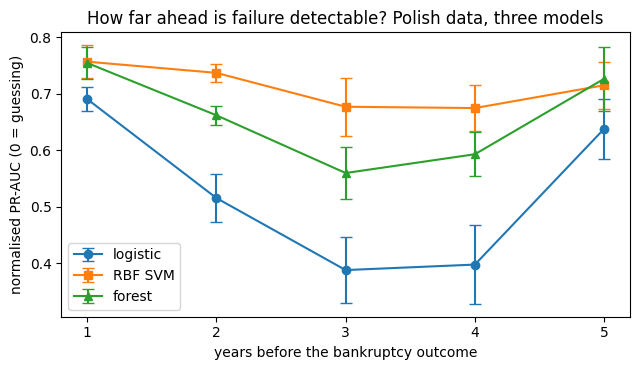

In [12]:
# Figure candidate: the RQ1 answer across three kinds of model
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for name, marker in [("logistic", "o"), ("RBF SVM", "s"), ("forest", "^")]:
    ax.errorbar(horizons["years_ahead"], horizons[name], yerr=horizons[f"{name}_sd"],
                fmt=f"{marker}-", capsize=4, label=name)
ax.set_xticks(range(1, 6))
ax.set_xlabel("years before the bankruptcy outcome")
ax.set_ylabel("normalised PR-AUC (0 = guessing)")
ax.set_title("How far ahead is failure detectable? Polish data, three models")
ax.legend()
plt.tight_layout()
plt.show()

**What we found** (normalised PR-AUC: 1 year → 3 years → 5 years):
- **Logistic:** 0.69 → 0.39 → 0.64 — the deep U from Week 4.
- **Random forest:** 0.75 → **0.56** → 0.73 — a shallow U.
- **RBF SVM:** 0.76 → **0.68** → 0.72 — nearly flat.
- **Both curved models shrink the dip a lot** (at 3 years: +0.17 for the forest, +0.29 for the SVM). The forest keeps
  part of it, so the honest reading is: the mid-horizon dip is **mostly, not entirely**, a straight-line effect.
- **At 1 and 5 years the two curved models agree closely** (0.75–0.76 and 0.72–0.73).
- **RQ1:** with a curved model, failure is detectable up to 5 years ahead at 0.56–0.76 of the possible improvement over
  guessing, with the weakest point at 3–4 years.

## Step 9 — RQ2 by horizon: does the important family change?

For each horizon: fit the forest on 80% of firms, then scramble each family on the other 20%.

In [13]:
by_h = {}
for h in range(1, 6):
    Xh, yh = load_polish(h)
    Xa, Xb, ya, yb = train_test_split(Xh, yh, test_size=0.2, stratify=yh, random_state=42)
    fams = {}
    for c in Xh.columns:
        fams.setdefault(family(c), []).append(c)
    m = rf_model().fit(Xa, ya)
    imp = family_importance(m, Xb, yb, fams, n_repeats=5)
    by_h[f"{h}y"] = imp.set_index("family")["PR_AUC_drop"]
horizon_families = pd.DataFrame(by_h).round(3)
horizon_families

,1y,2y,3y,4y,5y
family,,,,,
act,0.086,0.189,0.312,0.347,0.248
blank,0.523,0.527,0.528,0.460,0.607
lev,0.041,0.063,0.106,0.102,0.027
liq,0.038,0.100,0.071,0.145,0.050
prof,0.122,0.105,0.096,0.111,0.077
size,0.007,0.009,0.006,0.009,0.026


**How to read:** each number is the drop in PR-AUC when that family is scrambled, at that horizon. Bigger = the forest
relies on it more. Compare down each column (which family matters most at that horizon), then across (does it change?).
Each test part has only 20–80 bankrupt firms, so treat differences under about 0.05 as noise.

**What we found:**
- **Activity matters more the further ahead you look:** 0.09 (1 year) → 0.19 → 0.31 → **0.35** (4 years) → 0.25.
- **Blank flags are the top family at every horizon** (0.46–0.61).
- **Profitability is steady** (0.08–0.12) — never the main signal at any horizon.
- **Leverage and liquidity are small** (≤ 0.15) and move around within the noise.
- **RQ2, second half — the important family does shift with horizon:** near-term failure leans more on profitability
  and blank patterns; longer-range failure increasingly on activity ratios (how long a firm takes to pay its bills).
  A plausible reading: payment delays build up years before failure, while profits collapse closer to it.

## Step 10 — RQ3: Taiwanese data and its families

**Family mapping.** The Taiwanese ratios have plain-English names but no families. Each is assigned to the same
families as the Polish data by what it measures — a documented judgement, like the Polish mapping:
- **Profitability** — returns, margins, profit per share or per person, cash flow relative to sales, assets or equity.
- **Leverage** — debt relative to assets or equity, interest burden, cash flow relative to debt.
- **Liquidity** — short-term assets relative to short-term debt or total assets, working capital.
- **Activity** — turnover rates, collection days, revenue or allocation per person, expenses relative to assets.
- **Size** — total assets relative to GNP.
- **Other** — growth rates, net value or revenue per share, R&D expense, fixed-asset share.
- **Out** — the out-of-range flags from Week 4.

In [14]:
TW_FAMILIES = {
    "prof": ["ROA(C) before interest and depreciation before interest", "ROA(A) before interest and % after tax",
             "ROA(B) before interest and depreciation after tax", "Operating Gross Margin", "Realized Sales Gross Margin",
             "Operating Profit Rate", "Pre-tax net Interest Rate", "After-tax net Interest Rate",
             "Non-industry income and expenditure/revenue", "Continuous interest rate (after tax)",
             "Operating Expense Rate", "Cash flow rate", "Tax rate (A)", "Persistent EPS in the Last Four Seasons",
             "Cash Flow Per Share", "Operating Profit Per Share (Yuan ¥)", "Per Share Net profit before tax (Yuan ¥)",
             "Cash Reinvestment %", "Operating profit/Paid-in capital", "Net profit before tax/Paid-in capital",
             "Operating profit per person", "Retained Earnings to Total Assets", "Total income/Total expense",
             "Cash Flow to Sales", "Cash Flow to Total Assets", "CFO to Assets", "Cash Flow to Equity",
             "Net Income to Total Assets", "Gross Profit to Sales", "Net Income to Stockholder's Equity"],
    "lev":  ["Interest-bearing debt interest rate", "Interest Expense Ratio", "Total debt/Total net worth", "Debt ratio %",
             "Net worth/Assets", "Long-term fund suitability ratio (A)", "Borrowing dependency",
             "Contingent liabilities/Net worth", "Current Liability to Assets", "Operating Funds to Liability",
             "Current Liabilities/Liability", "Current Liabilities/Equity", "Long-term Liability to Current Assets",
             "Current Liability to Liability", "Current Liability to Equity", "Equity to Long-term Liability",
             "Cash Flow to Liability", "Liability-Assets Flag", "Liability to Equity",
             "Degree of Financial Leverage (DFL)", "Interest Coverage Ratio (Interest expense to EBIT)",
             "Equity to Liability"],
    "liq":  ["Current Ratio", "Quick Ratio", "Working Capital to Total Assets", "Quick Assets/Total Assets",
             "Current Assets/Total Assets", "Cash/Total Assets", "Quick Assets/Current Liability",
             "Cash/Current Liability", "Inventory/Working Capital", "Inventory/Current Liability",
             "Working Capital/Equity", "Current Liability to Current Assets", "No-credit Interval"],
    "act":  ["Inventory and accounts receivable/Net value", "Total Asset Turnover", "Accounts Receivable Turnover",
             "Average Collection Days", "Inventory Turnover Rate (times)", "Fixed Assets Turnover Frequency",
             "Net Worth Turnover Rate (times)", "Revenue per person", "Allocation rate per person",
             "Total expense/Assets", "Current Asset Turnover Rate", "Quick Asset Turnover Rate",
             "Working capitcal Turnover Rate", "Cash Turnover Rate"],
    "size": ["Total assets to GNP price"],
    "other": ["Research and development expense rate", "Net Value Per Share (B)", "Net Value Per Share (A)",
              "Net Value Per Share (C)", "Revenue Per Share (Yuan ¥)", "Realized Sales Gross Profit Growth Rate",
              "Operating Profit Growth Rate", "After-tax Net Profit Growth Rate", "Regular Net Profit Growth Rate",
              "Continuous Net Profit Growth Rate", "Total Asset Growth Rate", "Net Value Growth Rate",
              "Total Asset Return Growth Rate Ratio", "Fixed Assets to Assets"],
}

X_tw, y_tw = load_taiwan()
TW_FAMILIES["out"] = [c for c in X_tw.columns if c.startswith("out_")]
mapped = [c for cols in TW_FAMILIES.values() for c in cols]
assert sorted(mapped) == sorted(X_tw.columns), "every Taiwanese column must be mapped exactly once"
print({f: len(c) for f, c in TW_FAMILIES.items()})

{'prof': 30, 'lev': 22, 'liq': 13, 'act': 14, 'size': 1, 'other': 14, 'out': 24}


**Performance and family reliance in Taiwan.** Taiwan's test part would have only 44 bankrupt firms, so instead the
forest is scored with 5-fold cross-validation on all firms, and families are scrambled on each validation fold.

In [15]:
tw_logit = run_cv(scaled(LogisticRegression(max_iter=5000)), X_tw, y_tw)
tw_rf    = run_cv(rf_model(), X_tw, y_tw)
print(f"Taiwan — logistic: validation {tw_logit['val_PR_AUC']:.3f} (gap {tw_logit['gap']:.3f}) · "
      f"forest: validation {tw_rf['val_PR_AUC']:.3f} (gap {tw_rf['gap']:.3f})")

fold_imps = []
for k, (a, b) in enumerate(cv.split(X_tw, y_tw)):
    m = rf_model().fit(X_tw.iloc[a], y_tw.iloc[a])
    fold_imps.append(family_importance(m, X_tw.iloc[b], y_tw.iloc[b], TW_FAMILIES, n_repeats=3, seed=k)
                     .set_index("family")["PR_AUC_drop"])
tw_imp = pd.concat(fold_imps, axis=1).mean(axis=1).sort_values(ascending=False)
tw_imp = pd.DataFrame({"PR_AUC_drop": tw_imp, "n_columns": [len(TW_FAMILIES[f]) for f in tw_imp.index]})
tw_imp.round(3)

Taiwan — logistic: validation 0.446 (gap 0.188) · forest: validation 0.472 (gap 0.491)


,PR_AUC_drop,n_columns
family,,
prof,0.184,30
lev,0.140,22
liq,0.039,13
other,0.029,14
act,0.011,14
size,0.005,1
out,0.000,24


**Figure for the Milestone document (Figure 5).** Polish (Step 7) and Taiwanese family importance side by side. Each
panel shows each family's **share** of the total PR-AUC loss, because the two datasets have different scores; only
the ranking within each dataset is compared.

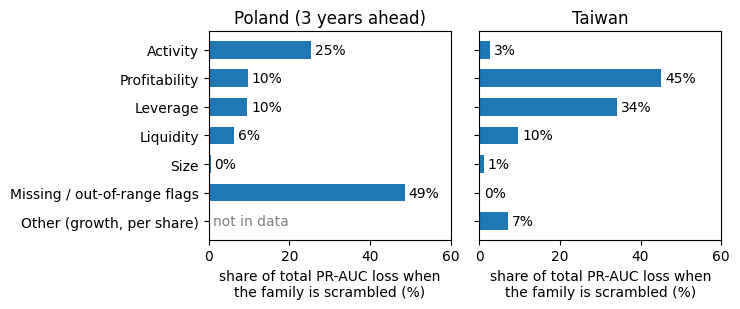

In [16]:
labels = {"act": "Activity", "prof": "Profitability", "lev": "Leverage", "liq": "Liquidity", "size": "Size",
          "blank": "Missing / out-of-range flags", "out": "Missing / out-of-range flags",
          "other": "Other (growth, per share)"}
order = ["Activity", "Profitability", "Leverage", "Liquidity", "Size",
         "Missing / out-of-range flags", "Other (growth, per share)"]
pl = fam_imp.set_index("family")["PR_AUC_drop"].rename(index=labels)
tw = tw_imp["PR_AUC_drop"].rename(index=labels)

fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.2), sharey=True)
for ax, (title, s) in zip(axes, [("Poland (3 years ahead)", pl), ("Taiwan", tw)]):
    share = s / s.sum() * 100
    for y, fam in enumerate(order[::-1]):
        if fam not in share.index:
            ax.text(1, y, "not in data", va="center", color="grey")
            continue
        ax.barh(y, share[fam], height=0.62, color="tab:blue")
        ax.text(share[fam] + 1, y, f"{share[fam]:.0f}%", va="center")
    ax.set_yticks(range(len(order)), order[::-1])
    ax.set_xlim(0, 60)
    ax.set_title(title)
    ax.set_xlabel("share of total PR-AUC loss when\nthe family is scrambled (%)")
plt.tight_layout()
plt.show()

**Polish (Step 7) vs Taiwanese ranking:** do the same families come out on top?

**What we found:**
- **Performance:** forest 0.472 vs logistic 0.446 — a small gain, but the forest's gap is 0.49 (logistic 0.19):
  with only 220 bankrupt firms it mostly memorises.
- **Taiwanese families:** profitability **0.184** · leverage **0.140** · liquidity 0.039 · other 0.029 ·
  activity **0.011** · size 0.005 · out-of-range flags 0.000.
- **Poland vs Taiwan — different families:**
  - Poland: blank patterns and **activity** lead; profitability and leverage are secondary (~0.10 each).
  - Taiwan: **profitability and leverage** lead; activity barely matters (0.011).
- **The out-of-range flags carry nothing** (0.000), unlike Poland's blank flags — Taiwan's odd values are a data
  quirk, not a warning sign.
- **RQ3 — the signal families do not transfer between markets.** The proposal asked whether Polish families "also
  dominate in Taiwanese data": they do not.
- **Caveat:** the Taiwanese family mapping is a judgement, and Taiwan has 30 profitability columns against 14 activity
  columns, so profitability has more chances to matter.

## Expected vs unexpected

These expectations were written **before** Week 6 ran: in the capstone proposal and the findings log (Weeks 3–5).

**Expected**
- Random-forest importance is the third view on RQ2, and families should agree "across at least two of three methods"
  (proposal) → activity is the top financial family for lasso, subset selection **and** the forest →
  **confirmed — all three agree**.
- A second non-linear model should confirm Week 5's flatter horizon pattern (findings log, Week 5) → the forest shrinks
  the mid-horizon dip (3 years: 0.39 → 0.56) but less than the SVM (0.68) → **mostly confirmed**.
- Polish families "also dominate in Taiwanese data" (proposal, RQ3) → Taiwan relies on profitability and leverage, not
  activity → **wrong**.
- Flexible models overfit where failures are scarce (Weeks 2, 4, 5) → Taiwan forest gap 0.49 → **confirmed**.

**Unexpected**
- **Activity's importance grows with horizon** (0.09 at 1 year → 0.35 at 4 years) — a horizon shift no earlier week showed.
- **A single small tree finds a 91%-bankrupt group** with three yes/no questions, starting from a blank value.
- **Taiwan's out-of-range flags carry no signal at all**, while Poland's blank flags are the strongest family.
- **One tree is no better than logistic regression** — the forest's gain comes entirely from averaging.

## Conclusions

1. **Decision tree — depth and overfitting:** validation peaks at depth 4 (0.368); with no limit, train 1.000 vs
   validation 0.189. Depth is the regulariser.
2. **What the tree asks:** "was interest coverage blank?" first; one three-question branch is 91% bankrupt. Every rule
   is a threshold.
3. **Random forest:** max_features 0.5, min_samples_leaf 5 → validation 0.545, far above one tree. Larger leaves are the
   main control on memorising.
4. **Test set:** RBF SVM 0.715, forest 0.674, logistic 0.485, tree 0.480. Two different curved models confirm the gain
   over straight lines.
5. **RQ2 — families (method 3 of 3):** blank patterns 0.52, activity 0.27, profitability 0.11, leverage 0.10,
   liquidity 0.07. **Activity is the top financial family for all three methods.**
6. **RQ1 — horizon:** curved models shrink Week 4's dip — forest 0.75 / 0.56 / 0.73, SVM 0.76 / 0.68 / 0.72 at 1 / 3 / 5
   years. Failure is detectable up to 5 years ahead; the dip is mostly, not entirely, a straight-line effect.
7. **RQ2 by horizon:** activity's importance grows from 0.09 (1 year) to 0.35 (4 years); blank patterns lead everywhere.
   The important family does shift with horizon.
8. **RQ3 — Taiwan:** profitability (0.18) and leverage (0.14) lead; activity barely matters (0.01). The Polish families
   do not transfer to Taiwan.
9. **Overfitting and hyperparameters:** depth (single tree), min_samples_leaf and max_features (forest) control
   memorising. Unlimited trees memorise completely (gap 0.81); averaging 500 trees plus leaves of 5 firms keeps the
   forest's test score high despite a large training fit (gap 0.31).